# Time of Onset of Symptoms to Transmission

Given two individuals $A$ and $B$ with $t_{\rm infec}^{(A)} < t_{\rm infec}^{(B)}$ we are interested in modelling the `Time from Onset of Symptoms to Transmission` $t_{\scriptscriptstyle \rm OST}$ of patient $A$ with respect to patient $B$:

$$
t_{\scriptscriptstyle \rm OST} = t_{\rm infec}^{(B)} - t_{\rm onset}^{(A)}
$$

In Ferretti et al. ([2020](https://doi.org/10.1101/2020.09.04.20188516)), given the `incubation time` $t_{i} = t_{\rm onset}^{(A)} - t_{\rm infec}^{(A)} > 0$ the probability of distribution of $t_{\scriptscriptstyle \rm OST} = t$ is modeled as a skew-logistic distribution (generalized logistic distribution of type I):

$$
\rho_{\scriptscriptstyle \rm OST}(t\vert t_{i})
=
\begin{cases}
&
\frac{1}{Z}
{e^{\frac{\mu- \tau t / t_i}{\sigma}}}
{\left(1+e^{\frac{\mu- \tau t / t_i}{\sigma}}\right)^{-\alpha-1}}
&
t  \in [-t_{i}, 0]
\\
&
\frac{1}{Z}
{e^{\frac{\mu-t}{\sigma}}}
{\left(1+e^{\frac{\mu-t}{\sigma}}\right)^{-\alpha-1}}
&
t > 0
.
\end{cases}
$$

Since the infection to patient $B$ could occur after the appearance of symptoms of $A$ (pre-symptomatic transmission), the time TOST $t$ can also be negative.
By definition $t \geq -t_{i}$ i. e. $t \in [-t_{i}, \infty)$.

### Cumulative distribution function

The cumulative distribution $F_{\scriptscriptstyle \rm OST}$ is given by

$$
F_{\scriptscriptstyle \rm OST}(t\vert t_{i})
=
\begin{cases}
&
\frac{1}{Z}
\frac{\sigma t_{i}}{\alpha \tau} \left[ \left(1+e^{\frac{\mu- \tau t / t_i}{\sigma}}\right)^{-\alpha} 
- \left(1+e^{\frac{\mu+\tau}{\sigma}}\right)^{-\alpha} \right]
&
t \in [t_{i}, 0]
\\
&
F_{\scriptscriptstyle \rm OST}(0\vert t_{i})
+
\frac{1}{Z}
\frac{\sigma}{\alpha} \left[ \left(1+e^{\frac{\mu-t}{\sigma}}\right)^{-\alpha} 
- \left(1+e^{\frac{\mu}{\sigma}}\right)^{-\alpha} \right]
&
t > 0
,
\end{cases}
$$

where 
$$
F_{\scriptscriptstyle \rm OST}(0\vert t_{i})
=
\frac{1}{Z}
\frac{\sigma t_{i}}{\alpha \tau} \left[ \left(1+e^{\frac{\mu}{\sigma}}\right)^{-\alpha} 
- \left(1+e^{\frac{\mu+\tau}{\sigma}}\right)^{-\alpha} \right]
$$

Finally the normalization constant is equal to 

$$
Z
=
\frac{\sigma}{\alpha}
\left[
    1 + \left(\frac{t_{i}}{\tau} - 1 \right) \left( 1 + e^{\frac{\mu}{\sigma}} \right)^{-\alpha} 
    - \frac{t_{i}}{\tau} \left(1+e^{\frac{\mu+\tau}{\sigma}}\right)^{-\alpha} 
\right]
$$

In [12]:
import numpy as np
import matplotlib.pyplot as plt

mIncub = 1.63
sdIncub = 0.5

t_incub = 5

kwargs = {
    "tau" : np.exp(mIncub + 0.5 * np.power(sdIncub, 2)),
    "mu_f" : -4.0,
    "sigma_f" : 1.85,
    "alpha_f" : 5.85
}

def norm( t_incub, ** kwargs ) :
    tau = kwargs["tau"]
    mu_f = kwargs["mu_f"]
    sigma_f = kwargs["sigma_f"]
    alpha_f = kwargs["alpha_f"]

    return sigma_f / alpha_f * ((1. + (t_incub/tau - 1.) * np.power(1. + np.exp(mu_f / sigma_f), - alpha_f))  - t_incub / tau * np.power(1.+np.exp((mu_f+tau)/sigma_f), -alpha_f))

def skew_logisitic_pdf(tost, t_incub, ** kwargs ) :
    tau = kwargs["tau"]
    mu_f = kwargs["mu_f"]
    sigma_f = kwargs["sigma_f"]
    alpha_f = kwargs["alpha_f"]

    if np.isscalar(tost):
        tost = np.array([tost])
    else:
        tost = np.asarray(tost)

    x = np.zeros(np.size(tost))
    x[tost <= 0] = tost[tost <= 0] * tau / t_incub
    x[tost > 0] = tost[tost > 0]
    y = np.exp((mu_f - x) / sigma_f) * np.power(1. + np.exp((mu_f - x) / sigma_f), - alpha_f - 1.) / norm(t_incub, ** kwargs)
    return y

x = np.linspace(-t_incub, 1e2, 1000000)
y = skew_logisitic_pdf(x, t_incub, ** kwargs)
print( "check normalization:", np.trapz(y, x) ) 

check normalization: 0.9999999999927458


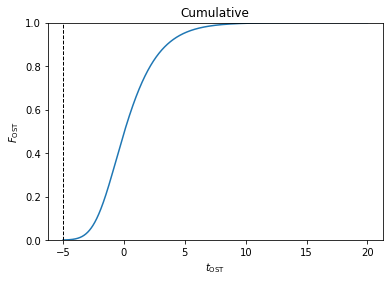

In [13]:
def skew_logisitic_cdf(tost, t_incub, ** kwargs) :
    tau = kwargs["tau"]
    mu_f = kwargs["mu_f"]
    sigma_f = kwargs["sigma_f"]
    alpha_f = kwargs["alpha_f"]

    if np.isscalar(tost):
        tost = np.array([tost])
    else:
        tost = np.asarray(tost)
        
    y = np.zeros(np.size(tost))

    # Integrate from -t_incub to tost
    y[tost <= 0] = t_incub / tau * (np.power(1. + np.exp((mu_f - tost[tost <= 0] * tau / t_incub) / sigma_f), -alpha_f) - np.power(1. + np.exp((mu_f + tau) / sigma_f), -alpha_f))
    # Integrate from -t_incub to 0
    tmp = t_incub / tau * (np.power(1. + np.exp(mu_f / sigma_f), -alpha_f) - np.power(1. + np.exp((mu_f + tau) / sigma_f), -alpha_f))
    # Integrate from 0 to tost
    y[tost > 0] += tmp + np.power(1. + np.exp((mu_f - tost[tost > 0]) / sigma_f), -alpha_f) - np.power(1. + np.exp(mu_f / sigma_f), -alpha_f)

    return y * sigma_f / (alpha_f * norm(t_incub, ** kwargs))

x = np.linspace(-t_incub, 2e1, 10000)
y = skew_logisitic_cdf(x, t_incub, ** kwargs)
plt.figure()
plt.title("Cumulative")
plt.xlabel(r"$t_{\rm OST}$")
plt.ylabel(r"$F_{\rm OST}$")
plt.plot(x, y)
plt.ylim([0,1])
plt.axvline(x=-t_incub, color="black", ls="--", lw=1)


### Transmission at onset time

It's easy to notice that $\rho_{\scriptscriptstyle \rm OST}(t = t_{i} \vert t_{i}) \neq 0$ since there's non-zero probability that the transmission to patient $B$ occurs at the moment of symptom onset of patient $A$.

<Figure size 432x288 with 0 Axes>

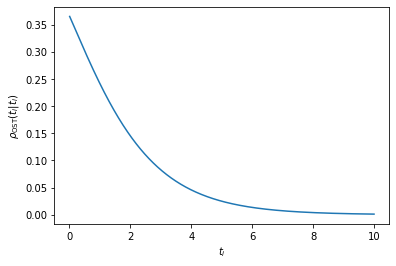

In [14]:
plt.figure()

x = np.linspace(0., 10., 1000)[1:]
y = np.array(list(map(lambda i : skew_logisitic_pdf(i, i, ** kwargs), x)))

plt.figure()
plt.xlabel(r"$t_{i}$")
plt.ylabel(r"$\rho_{\rm OST}(t_{i} \vert t_{i})$")
plt.plot(x, y)

# Extreme example
I want to model the risk of infection $A\to B$ in the same household from the probability of transmission :

$$
\lambda_{A\to B} (t_{\rm infec}^{(B)}) \varpropto \rho_{\scriptscriptstyle \rm OST}\left(t_{\rm infec}^{(B)} - t_{\rm onset}^{(A)} \Big\vert t_{\rm incub}^{(A)}\right)
.
$$

Let's assume only two residents, with patient $A$ `SYMPTOMATIC` and $B$ `HEALTHY`. What is the probability that $B$ "survived" until the end of the `study period` $T$ ? 

It will depend on the integral 

$$
\begin{aligned}
\exp - 
\int_{t_{\rm infec}^{(A)}}^{T} \lambda_{A\to B} (t) dt
&\simeq
\exp - 
\left[
F_{\scriptscriptstyle \rm OST} \left(T - t_{\rm onset}^{(A)} \Big\vert t_{\rm incub}^{(A)}\right)
-
F_{\scriptscriptstyle \rm OST} \left(t_{\rm infec}^{(A)} - t_{\rm onset}^{(A)} \Big\vert t_{\rm incub}^{(A)}\right)
\right]
\\
&\simeq
\exp - 
F_{\scriptscriptstyle \rm OST} \left(T - t_{\rm onset}^{(A)} \Big\vert t_{\rm incub}^{(A)}\right)
\end{aligned}
.
$$

Now, whatever the parameter multiplying $F_{\scriptscriptstyle \rm OST}$, this choice is problematic because it returns a higher probability of surviving for $T \simeq t_{\rm onset}^{(A)}$.

Since we augment the onset time without constrains, the larger likelihood will always be for diverging onset time of the symptomatic patients.

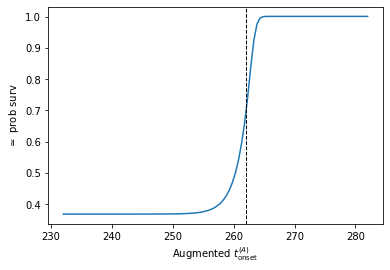

In [29]:
study_period = 262

t_onset_A = 232
t_incub_A = 3


t_augm_onset_A = np.linspace(t_onset_A, study_period + 20, 100)

# survival --> cdf at the end of study period
t_transm = study_period

tost = t_transm - t_augm_onset_A

y = np.exp(-skew_logisitic_cdf(tost, t_incub_A, ** kwargs))

plt.figure()
plt.xlabel(r"Augmented $t_{\rm onset}^{(A)}$")
plt.ylabel(r"$\simeq$ prob surv")
plt.plot(t_augm_onset_A, y)
plt.axvline(x=study_period, color="black", ls="--", lw=1)

If the time of the onset is much larger than the study period (which would be an incongruency of the data btw), the probability of surviving is clearly 1.

# Problem: a Probability is not a Rate

#
#
## >> Generate random OST times

We can use the cumulative distribution to extract random $t$ because of inversibility.